# Session 7 — Homework (before Session 8)

1. **Finalise the scoreboard** (Sessions 5–7, validation and test macro-F1) and bring the best model with its number.
2. **EfficientNet / DenseNet vs. ResNet**: one sentence.
3. **Optional:** fine-tune the whole network (strategy 3).

**Rules kept from the course:** same lesion-grouped split for every model; models are *selected on validation only*; each final model touches the **test set exactly once** (the notebook refuses to score a model on test twice).

> Runtime: with a GPU (Colab T4) the whole notebook takes roughly 10–15 min the first time. Trained weights and scores are cached in `outputs/session_07_hw/`, so re-running is fast. Set `RETRAIN = True` to train again.

## 0. Setup

In [1]:
# PURPOSE: libraries, project root, device. Robust to running from notebooks/ or session_07_cnns/.
import sys, time, json, copy, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
import torchvision.transforms as T
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import f1_score, recall_score, ConfusionMatrixDisplay, classification_report

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/ComputerVision_SpeechRecognition_Course")  # <- your Drive path
else:
    start = Path.cwd().resolve()
    candidates = [p for p in [start, *start.parents]
                  if (p / "data" / "milk10k" / "metadata.csv").is_file() or (p / "common" / "config.py").is_file()]
    if not candidates:
        raise FileNotFoundError("Run this notebook from inside the project folder (the one with data/ and common/).")
    ROOT = candidates[0]
sys.path.insert(0, str(ROOT))

device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("root:", ROOT, "| device:", device, "| torch", torch.__version__)

def seed_all(s=0):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
seed_all(0)

OUT = ROOT / "outputs" / "session_07_hw"
OUT.mkdir(parents=True, exist_ok=True)
RES_PATH = OUT / "results.json"
RETRAIN = False          # True = ignore saved weights and train again
results = json.load(open(RES_PATH)) if RES_PATH.exists() else {}
def save_results():
    json.dump(results, open(RES_PATH, "w"), indent=2)
count = lambda m: sum(p.numel() for p in m.parameters())

root: /Users/nairacampos/Desktop/MILK10k-Lesion-Classification/MILK10k-Lesion-Classification | device: mps | torch 2.14.0


## 1. Data: the same split as Sessions 5–7

First choice is your own `common` module (same split as before). If it is not importable, the fallback reads `metadata.csv` and builds a lesion-grouped, stratified 3593 / 599 / 1048 split with `StratifiedGroupKFold`. **The fallback split will not be identical to the one from earlier sessions**, so numbers from Sessions 5–6 would not be strictly comparable. The cell prints which path was used.

In [2]:
# PURPOSE: get train/val/test dataframes (dermoscopic image only, one row per lesion).
CLASSES = ["Benign", "Indeterminate", "Malignant"]
to_int = {c: i for i, c in enumerate(CLASSES)}
DATA = ROOT / "data" / "milk10k"

try:
    from common import config, milk10k
    df, gt = milk10k.load_metadata(), milk10k.load_gt()
    train_df, val_df, test_df = [d[d["image_type"] == "dermoscopic"].reset_index(drop=True)
                                 for d in milk10k.make_splits(df, gt, seed=0)]
    image_path = config.image_path
    SPLIT_SOURCE = "common.milk10k.make_splits (same as Sessions 5-7)"
except Exception as e:
    print("common module not usable:", repr(e))
    from sklearn.model_selection import StratifiedGroupKFold
    df = pd.read_csv(DATA / "metadata.csv")
    derm = df[df["image_type"] == "dermoscopic"].reset_index(drop=True)
    y_all = derm["diagnosis_1"].map(to_int)
    # 20% test (1 of 5 folds), then ~11.4% of the total as validation (1 of 7 folds of the rest)
    tr_val_idx, te_idx = next(StratifiedGroupKFold(5, shuffle=True, random_state=0).split(derm, y_all, derm["lesion_id"]))
    rest = derm.iloc[tr_val_idx].reset_index(drop=True)
    tr_idx, va_idx = next(StratifiedGroupKFold(7, shuffle=True, random_state=0).split(rest, rest["diagnosis_1"].map(to_int), rest["lesion_id"]))
    train_df, val_df, test_df = rest.iloc[tr_idx].reset_index(drop=True), rest.iloc[va_idx].reset_index(drop=True), derm.iloc[te_idx].reset_index(drop=True)
    image_path = lambda isic_id: DATA / "images" / f"{isic_id}.jpg"
    SPLIT_SOURCE = "FALLBACK split built here (not identical to earlier sessions)"

print("split source:", SPLIT_SOURCE)
print("sizes train/val/test:", len(train_df), len(val_df), len(test_df), "(Session 7 slides: 3593 / 599 / 1048)")
# Safety checks: no lesion on both sides of a split
assert not set(train_df.lesion_id) & set(val_df.lesion_id) and not set(train_df.lesion_id) & set(test_df.lesion_id) and not set(val_df.lesion_id) & set(test_df.lesion_id), "lesion leakage!"
print(pd.DataFrame({n: d["diagnosis_1"].value_counts() for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]}))

common module not usable: ImportError("cannot import name 'config' from 'common' (/Users/nairacampos/Desktop/MILK10k-Lesion-Classification/MILK10k-Lesion-Classification/common/__init__.py)")
split source: FALLBACK split built here (not identical to earlier sessions)
sizes train/val/test: 3593 599 1048 (Session 7 slides: 3593 / 599 / 1048)
               train  val  test
diagnosis_1                    
Malignant       2492  415   727
Benign          1017  169   297
Indeterminate     84   15    24


In [3]:
# PURPOSE: decode every image once as uint8 224x224 and cache it (Session 7, 4.2).
# The cache is shared with session_07.ipynb ONLY if the split source is the same.
tag = "" if SPLIT_SOURCE.startswith("common") else "_fallback"
cache = ROOT / "session_07_cnns" / "_output" / f"images_224{tag}.pt"
if cache.exists():
    data = torch.load(cache)
else:
    t0 = time.perf_counter(); data = {}
    for name, split in [("train", train_df), ("val", val_df), ("test", test_df)]:
        X = torch.empty((len(split), 3, 224, 224), dtype=torch.uint8)
        for i, isic_id in enumerate(split["isic_id"]):
            img = Image.open(image_path(isic_id)).convert("RGB").resize((224, 224))
            X[i] = torch.from_numpy(np.array(img)).permute(2, 0, 1)
        data[f"X_{name}"] = X
        data[f"y_{name}"] = torch.tensor(split["diagnosis_1"].map(to_int).to_numpy())
    cache.parent.mkdir(exist_ok=True); torch.save(data, cache)
    print(f"built cache in {time.perf_counter() - t0:.0f} s")
X_train, y_train = data["X_train"], data["y_train"]
X_val, y_val = data["X_val"], data["y_val"]
X_test, y_test = data["X_test"], data["y_test"]
# Cache must match the current split
assert len(X_train) == len(train_df) and len(X_val) == len(val_df) and len(X_test) == len(test_df), "stale cache: delete it"
print(X_train.shape, X_train.dtype, torch.bincount(y_train))

torch.Size([3593, 3, 224, 224]) torch.uint8 tensor([1017,   84, 2492])


## 2. Shared toolkit (identical to Session 7)

In [4]:
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
def prep(xb):
    return (xb.to(device).float() / 255 - MEAN) / STD

def augment(xb):
    n = xb.size(0)
    flip_h = torch.rand(n, 1, 1, 1, device=xb.device) < 0.5
    xb = torch.where(flip_h, xb.flip(3), xb)
    flip_v = torch.rand(n, 1, 1, 1, device=xb.device) < 0.5
    return torch.where(flip_v, xb.flip(2), xb)

class_weights = (len(y_train) / (3 * torch.bincount(y_train).float())).to(device)

@torch.no_grad()
def predict(model, X, batch_size=128):
    model.eval()
    return torch.cat([model(prep(X[i:i + batch_size])).argmax(1).cpu() for i in range(0, len(X), batch_size)])

def fit(model, params, epochs, lr, batch_size=64, aug=True):
    """Session 6/7 loop. `params` may be a list of tensors or a list of param-group dicts."""
    model.to(device)
    optimizer = torch.optim.Adam(params, lr=lr)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights)
    history, best = [], {"f1": -1}
    for epoch in range(epochs):
        model.train(); t0, total = time.perf_counter(), 0.0
        order = torch.randperm(len(X_train))
        for i in range(0, len(X_train), batch_size):
            idx = order[i:i + batch_size]
            xb, yb = prep(X_train[idx]), y_train[idx].to(device)
            if aug: xb = augment(xb)
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(idx)
        f1 = f1_score(y_val, predict(model, X_val), average="macro")
        history.append({"epoch": epoch, "train_loss": total / len(X_train), "val_f1": f1})
        print(f"epoch {epoch} loss {total / len(X_train):.3f} val macro-F1 {f1:.3f} ({time.perf_counter() - t0:.0f} s)")
        if f1 > best["f1"]:
            best = {"f1": f1, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}
    model.load_state_dict(best["state"])      # early stopping: keep the best epoch (chosen on VALIDATION)
    return pd.DataFrame(history).set_index("epoch"), best

# --- bookkeeping: validation score for every model; test score only once, at the very end ---
predictors = {}   # name -> function(split_name) -> predictions

def train_or_load(name, model, params, epochs, lr, n_trainable=None):
    ckpt = OUT / f"{name}.pt"
    model.to(device)
    if ckpt.exists() and not RETRAIN:
        model.load_state_dict(torch.load(ckpt, map_location=device)); print(f"[{name}] loaded saved weights")
    else:
        t0 = time.perf_counter()
        hist, best = fit(model, params, epochs, lr)
        torch.save(model.state_dict(), ckpt)
        results.setdefault(name, {}).update(best_epoch=int(best["epoch"]), sec_per_epoch=(time.perf_counter() - t0) / epochs)
        hist.to_csv(OUT / f"{name}_history.csv")
    X = {"val": X_val, "test": X_test}
    predictors[name] = lambda split, m=model: predict(m, X[split])
    pv = predictors[name]("val")
    results.setdefault(name, {}).update(
        val_f1=float(f1_score(y_val, pv, average="macro")),
        val_recall=[float(r) for r in recall_score(y_val, pv, average=None, labels=[0, 1, 2])],
        params_trained=int(n_trainable if n_trainable is not None else count(model)))
    save_results()
    print(f"[{name}] val macro-F1 = {results[name]['val_f1']:.3f}")

## 3. Models of Session 7 (rebuilt, so the scoreboard is reproducible)

| name | what is trained |
|---|---|
| `scratch_cnn` | SimpleCNN from random weights |
| `resnet18_frozen_head` | frozen ResNet-18 + new `Linear(512,3)` on cached embeddings |
| `resnet18_layer4` | layer4 + head (lr 1e-4) |
| `resnet18_layer3_4` | layer3 + layer4 + head (lr 1e-4), the mini challenge |
| `resnet18_full` | **strategy 3: every layer**, with discriminative learning rates |

In [5]:
class SimpleCNN(nn.Module):
    def __init__(self, n_classes=3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(32 * 56 * 56, n_classes))
    def forward(self, x):
        return self.classifier(self.features(x))

seed_all(0)
scratch = SimpleCNN()
train_or_load("scratch_cnn", scratch, scratch.parameters(), epochs=10, lr=1e-3)

[scratch_cnn] loaded saved weights
[scratch_cnn] val macro-F1 = 0.554


In [6]:
# Frozen ResNet-18 as feature extractor (512 learned numbers per lesion) + linear head.
seed_all(0)
backbone = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
backbone.fc = nn.Identity(); backbone.to(device).eval()

@torch.no_grad()
def embed(X, batch_size=128):
    return torch.cat([backbone(prep(X[i:i + batch_size])).cpu() for i in range(0, len(X), batch_size)])

emb_cache = OUT / "embeddings.pt"
if emb_cache.exists() and not RETRAIN:
    F_train, F_val, F_test = torch.load(emb_cache)
else:
    F_train, F_val, F_test = embed(X_train), embed(X_val), embed(X_test)
    torch.save((F_train, F_val, F_test), emb_cache)

from torch.utils.data import DataLoader, TensorDataset
head = nn.Linear(512, 3).to(device)
head_ckpt = OUT / "resnet18_frozen_head.pt"
if head_ckpt.exists() and not RETRAIN:
    head.load_state_dict(torch.load(head_ckpt, map_location=device)); print("[frozen head] loaded")
else:
    opt = torch.optim.Adam(head.parameters(), lr=1e-3)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights)
    loader = DataLoader(TensorDataset(F_train, y_train), batch_size=64, shuffle=True)
    best_f1, best_state = -1, None
    for epoch in range(25):
        head.train()
        for fb, yb in loader:
            opt.zero_grad(); loss_fn(head(fb.to(device)), yb.to(device)).backward(); opt.step()
        with torch.no_grad():
            f1 = f1_score(y_val, head(F_val.to(device)).argmax(1).cpu(), average="macro")
        if f1 > best_f1: best_f1, best_state = f1, copy.deepcopy(head.state_dict())
    head.load_state_dict(best_state); torch.save(head.state_dict(), head_ckpt)

feats = {"val": F_val, "test": F_test}
@torch.no_grad()
def head_predict(split):
    head.eval(); return head(feats[split].to(device)).argmax(1).cpu()
predictors["resnet18_frozen_head"] = head_predict
pv = head_predict("val")
results["resnet18_frozen_head"] = {**results.get("resnet18_frozen_head", {}),
    "val_f1": float(f1_score(y_val, pv, average="macro")),
    "val_recall": [float(r) for r in recall_score(y_val, pv, average=None, labels=[0, 1, 2])],
    "params_trained": count(head)}
save_results()
print("[resnet18_frozen_head] val macro-F1 =", round(results["resnet18_frozen_head"]["val_f1"], 3), "(Session 7 run: 0.632)")

[frozen head] loaded
[resnet18_frozen_head] val macro-F1 = 0.637 (Session 7 run: 0.632)


In [7]:
def make_resnet(trainable_prefixes):
    """Fresh pretrained ResNet-18, new 3-class head, only layers starting with these prefixes are trained."""
    m = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    m.fc = nn.Linear(512, 3)
    for name, p in m.named_parameters():
        p.requires_grad = any(name.startswith(pref) for pref in trainable_prefixes)
    trainable = [p for p in m.parameters() if p.requires_grad]
    return m, trainable, sum(p.numel() for p in trainable)

seed_all(0)
m4, tr4, n4 = make_resnet(["layer4", "fc"])
print(f"layer4 + fc: training {n4:,} of {count(m4):,} parameters")
train_or_load("resnet18_layer4", m4, tr4, epochs=6, lr=1e-4, n_trainable=n4)

layer4 + fc: training 8,395,267 of 11,178,051 parameters
[resnet18_layer4] loaded saved weights
[resnet18_layer4] val macro-F1 = 0.644


### Mini challenge (Section 11): also unfreeze `layer3`

In [8]:
seed_all(0)
m34, tr34, n34 = make_resnet(["layer3", "layer4", "fc"])
print(f"layer3 + layer4 + fc: training {n34:,} of {count(m34):,} parameters")
train_or_load("resnet18_layer3_4", m34, tr34, epochs=6, lr=1e-4, n_trainable=n34)
for k in ["resnet18_layer4", "resnet18_layer3_4"]:
    r = results[k]; print(f"{k:20s} params {r['params_trained']:>10,} | {r.get('sec_per_epoch', float('nan')):5.1f} s/epoch | val macro-F1 {r['val_f1']:.3f}")

layer3 + layer4 + fc: training 10,494,979 of 11,178,051 parameters
epoch 0 loss 0.864 val macro-F1 0.538 (55 s)
epoch 1 loss 0.575 val macro-F1 0.626 (11 s)
epoch 2 loss 0.487 val macro-F1 0.665 (12 s)
epoch 3 loss 0.360 val macro-F1 0.604 (11 s)
epoch 4 loss 0.329 val macro-F1 0.642 (11 s)
epoch 5 loss 0.241 val macro-F1 0.665 (12 s)
[resnet18_layer3_4] val macro-F1 = 0.665
resnet18_layer4      params  8,395,267 |   9.3 s/epoch | val macro-F1 0.644
resnet18_layer3_4    params 10,494,979 |  18.7 s/epoch | val macro-F1 0.665


## 4. Optional: strategy 3, fine-tune the whole network

All 11.2 M weights are trained, but not at the same speed. Early layers hold generic edges and colours learned from 1.28 M photos, so they get a **tiny** learning rate; layer4 gets a moderate one; the brand-new head gets the largest. This is *discriminative learning rates*, and it limits the risk of destroying good pretrained filters with only 3,593 lesions.

In [9]:
seed_all(0)
mfull, _, _ = make_resnet(["conv1", "bn1", "layer1", "layer2", "layer3", "layer4", "fc"])
nfull = count(mfull)
groups = [
    {"params": list(mfull.conv1.parameters()) + list(mfull.bn1.parameters()) + list(mfull.layer1.parameters()) + list(mfull.layer2.parameters()), "lr": 1e-5},
    {"params": mfull.layer3.parameters(), "lr": 3e-5},
    {"params": mfull.layer4.parameters(), "lr": 1e-4},
    {"params": mfull.fc.parameters(),     "lr": 1e-3},
]
print(f"training all {nfull:,} parameters")
train_or_load("resnet18_full", mfull, groups, epochs=8, lr=1e-4, n_trainable=nfull)   # lr is only the default; every group sets its own

training all 11,178,051 parameters
epoch 0 loss 0.910 val macro-F1 0.546 (19 s)
epoch 1 loss 0.614 val macro-F1 0.646 (18 s)
epoch 2 loss 0.493 val macro-F1 0.641 (18 s)
epoch 3 loss 0.377 val macro-F1 0.632 (18 s)
epoch 4 loss 0.356 val macro-F1 0.636 (18 s)
epoch 5 loss 0.285 val macro-F1 0.675 (19 s)
epoch 6 loss 0.227 val macro-F1 0.668 (19 s)
epoch 7 loss 0.186 val macro-F1 0.630 (19 s)
[resnet18_full] val macro-F1 = 0.675


## 5. Scoreboard (Sessions 5–7)

* **Majority** is computed here exactly (always predict the most common training class).
* **Sessions 5–6** models were trained in your earlier notebooks. Type their numbers in the dictionary below (validation numbers from the slides are pre-filled; the test numbers and the MLP are yours to fill in from `session_05_hw` / `session_06_hw`, or point the cell to a saved file). Anything left as `None` shows as `NaN`.
* **Session 7** models are scored on **test exactly once** in the cell after next.

In [10]:
# >>> EDIT HERE: numbers from your own Session 5 and 6 notebooks (macro-F1). None = not filled in yet.
PRIOR = {
    "Session 5 · logistic regression": {"val_f1": 0.437, "test_f1": None},
    "Session 5 · kNN (k=5)":           {"val_f1": 0.474, "test_f1": None},
    "Session 5 · random forest":       {"val_f1": 0.534, "test_f1": None},
    "Session 6 · MLP (33 features)":   {"val_f1": None,  "test_f1": None},
}
# Optional: a CSV with columns model,val_f1,test_f1 saved by the earlier notebooks
for p in [ROOT / "outputs" / "scoreboard.csv", ROOT / "reports" / "scoreboard.csv", ROOT / "notebooks" / "outputs" / "scoreboard.csv"]:
    if p.exists():
        sb = pd.read_csv(p); print("loaded", p)
        for _, r in sb.iterrows(): PRIOR[r["model"]] = {"val_f1": r["val_f1"], "test_f1": r["test_f1"]}
        break

# Majority baseline, exact
maj = torch.bincount(y_train).argmax().item()
for split, y in [("val", y_val), ("test", y_test)]:
    results.setdefault("majority", {})[f"{split}_f1"] = float(f1_score(y, np.full(len(y), maj), average="macro"))
print("majority class:", CLASSES[maj], "| val", round(results["majority"]["val_f1"], 3), "| test", round(results["majority"]["test_f1"], 3))
save_results()

majority class: Malignant | val 0.273 | test 0.273


### Test scoring (one time per model)
Selection of the best model is done on **validation**; the test numbers below are reported, never used to choose or tune.

In [11]:
test_preds = {}
for name, pred_fn in predictors.items():
    if "test_f1" in results[name]:
        print(f"[{name}] test already scored earlier (not recomputed): {results[name]['test_f1']:.3f}")
        continue
    pt = pred_fn("test")
    test_preds[name] = pt.numpy()
    results[name]["test_f1"] = float(f1_score(y_test, pt, average="macro"))
    results[name]["test_recall"] = [float(r) for r in recall_score(y_test, pt, average=None, labels=[0, 1, 2])]
    np.save(OUT / f"{name}_test_pred.npy", pt.numpy())
    save_results()
    print(f"[{name}] test macro-F1 = {results[name]['test_f1']:.3f}")

[scratch_cnn] test macro-F1 = 0.518
[resnet18_frozen_head] test macro-F1 = 0.578
[resnet18_layer4] test macro-F1 = 0.600
[resnet18_layer3_4] test macro-F1 = 0.614
[resnet18_full] test macro-F1 = 0.618


,model,val_f1,test_f1,params_trained,recall_Indeterminate_test,recall_Malignant_test,recall_Benign_test
0,Session 5 · majority class,0.273,0.273,0.000,–,–,–
1,Session 5 · logistic regression,0.437,–,–,–,–,–
2,Session 5 · kNN (k=5),0.474,–,–,–,–,–
3,Session 5 · random forest,0.534,–,–,–,–,–
4,Session 6 · MLP (33 features),–,–,–,–,–,–
5,Session 7 · CNN from scratch,0.554,0.518,306147.000,0.125,0.750,0.727
6,Session 7 · ResNet-18 frozen + head,0.637,0.578,1539.000,0.417,0.821,0.630
7,Session 7 · ResNet-18 fine-tune layer4,0.644,0.600,8395267.000,0.417,0.772,0.744
8,Session 7 · ResNet-18 fine-tune layer3+4,0.665,0.614,10494979.000,0.458,0.774,0.744
9,Session 7 · ResNet-18 fine-tune ALL,0.675,0.618,11178051.000,0.500,0.768,0.747


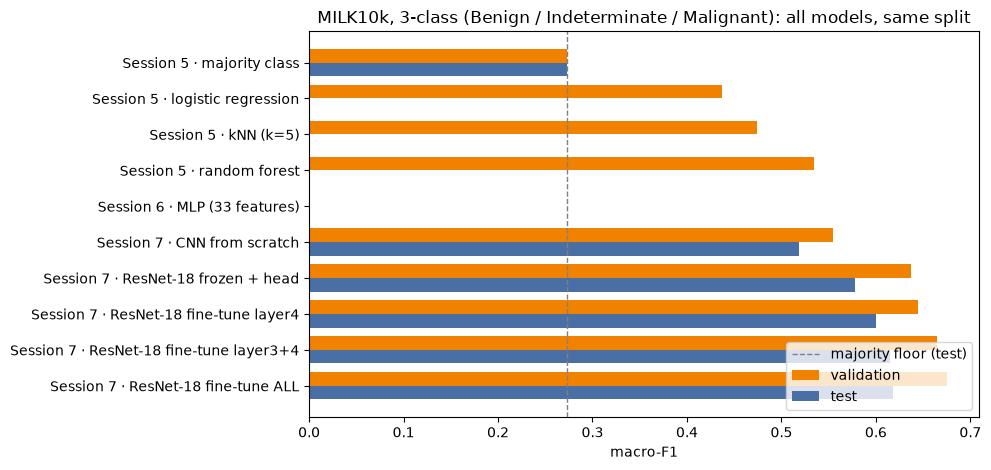

In [12]:
LABELS = {"scratch_cnn": "Session 7 · CNN from scratch",
          "resnet18_frozen_head": "Session 7 · ResNet-18 frozen + head",
          "resnet18_layer4": "Session 7 · ResNet-18 fine-tune layer4",
          "resnet18_layer3_4": "Session 7 · ResNet-18 fine-tune layer3+4",
          "resnet18_full": "Session 7 · ResNet-18 fine-tune ALL"}
rows = [{"model": "Session 5 · majority class", "val_f1": results["majority"]["val_f1"], "test_f1": results["majority"]["test_f1"], "params_trained": 0}]
rows += [{"model": k, "val_f1": v["val_f1"], "test_f1": v["test_f1"], "params_trained": None} for k, v in PRIOR.items()]
for k, lab in LABELS.items():
    if k in results and "test_f1" in results[k]:
        rows.append({"model": lab, "val_f1": results[k]["val_f1"], "test_f1": results[k]["test_f1"], "params_trained": results[k]["params_trained"],
                     "recall_Indeterminate_test": results[k]["test_recall"][1], "recall_Malignant_test": results[k]["test_recall"][2],
                     "recall_Benign_test": results[k]["test_recall"][0]})
board = pd.DataFrame(rows)
board.to_csv(OUT / "scoreboard.csv", index=False)
display(board.round(3).style.format(precision=3, na_rep="–").background_gradient(subset=["val_f1", "test_f1"], cmap="Oranges"))

fig, ax = plt.subplots(figsize=(10, 4.8))
y = np.arange(len(board)); h = 0.38
ax.barh(y - h/2, board["val_f1"], h, label="validation", color="#F08200")
ax.barh(y + h/2, board["test_f1"], h, label="test", color="#4a6fa5")
ax.set_yticks(y); ax.set_yticklabels(board["model"]); ax.invert_yaxis()
ax.axvline(results["majority"]["test_f1"], color="gray", ls="--", lw=1, label="majority floor (test)")
ax.set_xlabel("macro-F1"); ax.set_title("MILK10k, 3-class (Benign / Indeterminate / Malignant): all models, same split")
ax.legend(loc="lower right"); plt.tight_layout()
plt.savefig(OUT / "scoreboard.png", dpi=150); plt.show()

## 6. The best model, chosen on validation

BEST SESSION-7 MODEL (selected on validation): Session 7 · ResNet-18 fine-tune ALL
  validation macro-F1 = 0.675   |   test macro-F1 = 0.618
  recall on test: Benign 0.75 · Indeterminate 0.50 · Malignant 0.77
  vs. Session 5 random forest (val 0.534): +0.141 macro-F1 on validation
  trainable parameters: 11,178,051

Note: with 599 validation lesions and only 83+17 Indeterminate cases, differences below ~0.02-0.03 are within noise.


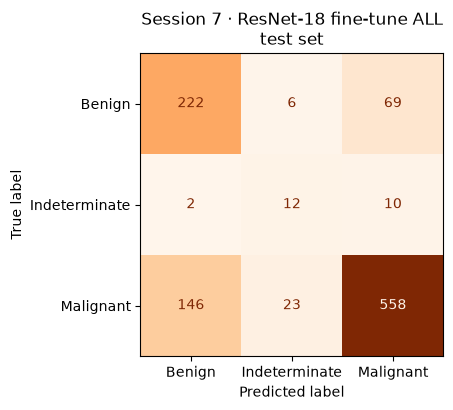

               precision    recall  f1-score   support

       Benign      0.600     0.747     0.666       297
Indeterminate      0.293     0.500     0.369        24
    Malignant      0.876     0.768     0.818       727

     accuracy                          0.756      1048
    macro avg      0.590     0.672     0.618      1048
 weighted avg      0.784     0.756     0.765      1048



In [13]:
s7 = {k: results[k] for k in LABELS if k in results and "test_f1" in results[k]}
best_name = max(s7, key=lambda k: s7[k]["val_f1"])
b = results[best_name]
print(f"BEST SESSION-7 MODEL (selected on validation): {LABELS[best_name]}")
print(f"  validation macro-F1 = {b['val_f1']:.3f}   |   test macro-F1 = {b['test_f1']:.3f}")
print(f"  recall on test: Benign {b['test_recall'][0]:.2f} · Indeterminate {b['test_recall'][1]:.2f} · Malignant {b['test_recall'][2]:.2f}")
print(f"  vs. Session 5 random forest (val 0.534): {b['val_f1'] - 0.534:+.3f} macro-F1 on validation")
print(f"  trainable parameters: {b['params_trained']:,}")
print()
print("Note: with 599 validation lesions and only 83+17 Indeterminate cases, differences below ~0.02-0.03 are within noise.")

fig, ax = plt.subplots(figsize=(4.8, 4.2))
ConfusionMatrixDisplay.from_predictions(y_test, predictors[best_name]("test") if best_name not in test_preds else test_preds[best_name],
                                        display_labels=CLASSES, cmap="Oranges", ax=ax, colorbar=False)
ax.set_title(f"{LABELS[best_name]}\ntest set"); plt.tight_layout()
plt.savefig(OUT / "best_model_confusion_test.png", dpi=150); plt.show()
print(classification_report(y_test, predictors[best_name]("test"), target_names=CLASSES, digits=3, zero_division=0))

> **Why the confusion matrix is on test here:** the test predictions of every model were already produced once in the scoring cell; this plot only re-reads the best model's saved predictions (no tuning is based on it).

## 7. EfficientNet / DenseNet vs. ResNet — one sentence each

* **DenseNet:** where ResNet *adds* a block's input to its output (`x + F(x)`), DenseNet *concatenates* the feature maps of every earlier layer as input to each new layer, so features are reused directly, with fewer parameters per layer and stronger gradient flow.
* **EfficientNet:** instead of making a ResNet deeper *or* wider *or* fed with larger images by hand, it scales depth, width and input resolution together with one fixed *compound* coefficient, on a base network built from efficient MBConv blocks (with squeeze-and-excitation), reaching ResNet-level accuracy with several times fewer parameters.